<a href="https://colab.research.google.com/github/eman-25/BehaviQ/blob/main/Bahrain_Customer_Churn_Analysis_Improved_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Analysis - Refactored & Production-Ready

**Run order:** Runtime → *Run all*. Sections: shared module → config → data → EDA → model comparison → evaluation → explainability → portfolio report → save artifacts → dashboard app (upload-and-analyze platform) → launch.

**Before you share this notebook:** the original version contained a live ngrok auth token in plain text. Treat it as compromised and **revoke it** at dashboard.ngrok.com, then store the new one as a Colab *Secret* (see the last cell).

**Data note:** the dataset is IBM's public *Telco* sample (US-style telecom data), not Bahraini customer data. Currency labels are therefore configurable and **no BHD conversion is applied**. To analyse real Bahrain data, point `DATA_SOURCE` to your CSV with the same columns.

## 1. Shared module (`churn_lib.py`)
Cleaning, feature engineering and the model pipeline live in one file so the notebook and the app run *identical* preprocessing.

In [ ]:
%%writefile churn_lib.py
"""Shared building blocks for the churn project.

Both the training notebook and the Streamlit app import from this module, so the
exact same preprocessing is applied at training and at prediction time. (A
custom transformer defined inside a notebook cannot be unpickled by another
process, which is why this lives in its own file.)
"""
from __future__ import annotations

from typing import Dict, Tuple

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (HistGradientBoostingClassifier,
                              RandomForestClassifier, VotingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = "Churn"
ID_COL = "customerID"
DATA_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
            "master/data/Telco-Customer-Churn.csv")

RAW_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
ADDON_SERVICES = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                  "TechSupport", "StreamingTV", "StreamingMovies"]
AUTOPAY_METHODS = ("Bank transfer (automatic)", "Credit card (automatic)")
CATEGORICAL = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
               "MultipleLines", "InternetService", *ADDON_SERVICES, "Contract",
               "PaperlessBilling", "PaymentMethod"]
ENGINEERED_NUMERIC = ["n_addon_services", "avg_monthly_spend", "is_autopay"]
RAW_FEATURES = RAW_NUMERIC + CATEGORICAL


# --------------------------------------------------------------------------- #
# Data loading & cleaning
# --------------------------------------------------------------------------- #
def load_and_clean(source: str = DATA_URL) -> Tuple[pd.DataFrame, pd.Series]:
    """Load the raw CSV, validate its schema, clean it and return ``(X, y)``.

    Cleaning rules
    --------------
    * whitespace is stripped from text columns;
    * ``TotalCharges`` is blank only for customers with ``tenure == 0`` (they have
      not been billed yet) so the correct value is 0 - not the column median;
    * ``SeniorCitizen`` (0/1) becomes a Yes/No category like the other flags;
    * the target is mapped to 1 (churned) / 0 (stayed).
    """
    df = pd.read_csv(source)
    missing = {*RAW_FEATURES, TARGET} - set(df.columns)
    if missing:
        raise ValueError(f"Dataset is missing expected columns: {sorted(missing)}")

    df = df.drop(columns=[c for c in (ID_COL,) if c in df.columns])
    for col in df.select_dtypes(exclude="number").columns:
        df[col] = df[col].astype("string").str.strip()

    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").astype("float64")
    df.loc[df["TotalCharges"].isna() & (df["tenure"] == 0), "TotalCharges"] = 0.0
    df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
    for col in CATEGORICAL:
        df[col] = df[col].astype(object)

    y = df[TARGET].map({"Yes": 1, "No": 0})
    if y.isna().any():
        raise ValueError("Target column contains values other than Yes/No.")
    return df[RAW_FEATURES].copy(), y.astype(int)


# --------------------------------------------------------------------------- #
# Feature engineering + model pipeline
# --------------------------------------------------------------------------- #
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Adds a few business-driven features (stateless, so leakage-free)."""

    def fit(self, X: pd.DataFrame, y=None) -> "FeatureEngineer":
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X = X.copy()
        X["n_addon_services"] = (X[ADDON_SERVICES] == "Yes").sum(axis=1)
        X["avg_monthly_spend"] = X["TotalCharges"] / X["tenure"].clip(lower=1)
        X["is_autopay"] = X["PaymentMethod"].isin(AUTOPAY_METHODS).astype(int)
        return X


def build_pipeline(model) -> Pipeline:
    """raw DataFrame -> feature engineering -> impute/scale/encode -> model."""
    from sklearn.impute import SimpleImputer

    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    prep = ColumnTransformer(
        [("num", numeric, RAW_NUMERIC + ENGINEERED_NUMERIC),
         ("cat", categorical, CATEGORICAL)],
        verbose_feature_names_out=False)
    return Pipeline([("features", FeatureEngineer()), ("prep", prep), ("model", model)])


def get_candidate_models() -> Dict[str, Pipeline]:
    """Candidate models. Probabilities are kept un-reweighted on purpose so they
    stay close to true churn probabilities; imbalance is handled by tuning the
    decision threshold instead of class weights."""
    lr = LogisticRegression(C=0.5, max_iter=2000, random_state=RANDOM_STATE)
    rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=10, n_jobs=-1,
                                random_state=RANDOM_STATE)
    hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200,
                                         max_leaf_nodes=15, l2_regularization=1.0,
                                         random_state=RANDOM_STATE)
    ensemble = VotingClassifier([("lr", lr), ("rf", rf), ("hgb", hgb)], voting="soft")
    return {name: build_pipeline(m) for name, m in
            {"Logistic Regression": lr, "Random Forest": rf,
             "Gradient Boosting": hgb, "Soft-Voting Ensemble": ensemble}.items()}


def best_f1_threshold(y_true, proba) -> float:
    """Probability cut-off that maximises F1 (use out-of-fold predictions!)."""
    prec, rec, thr = precision_recall_curve(y_true, proba)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[int(np.argmax(f1))])

Overwriting churn_lib.py


## 2. Setup, configuration and chart theme

In [ ]:
# ============================================================================
# Imports, configuration and chart theme
# ============================================================================
import json
import platform
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from matplotlib.ticker import PercentFormatter
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)

import churn_lib as lib

# --- Configuration (edit here) ----------------------------------------------
DATA_SOURCE = lib.DATA_URL        # URL or local CSV path; swap in your own billing data
CURRENCY = "USD"                  # label only - NO currency conversion is applied
TEST_SIZE = 0.20
CV_FOLDS = 5
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

# --- Executive-friendly visual theme ----------------------------------------
PAL = {"navy": "#1F3A5F", "teal": "#2A9D8F", "coral": "#E76F51",
       "gold": "#E9C46A", "grey": "#8D99AE", "ink": "#243B53"}
STAY, CHURN = PAL["teal"], PAL["coral"]


def set_theme() -> None:
    """Apply one consistent, presentation-ready look to every chart."""
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.edgecolor": "#CBD2D9", "grid.color": "#E4E7EB", "axes.grid.axis": "y",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlecolor": PAL["ink"],
        "axes.labelsize": 11, "axes.labelcolor": PAL["ink"],
        "xtick.color": PAL["ink"], "ytick.color": PAL["ink"], "legend.frameon": False,
    })


def headline(fig, title: str, subtitle: str = "") -> None:
    """Consistent title + subtitle block; also lays out the figure beneath it."""
    h = fig.get_figheight()                      # offsets in inches -> same look at any size
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.85 / h))
    fig.text(0.01, 1 - 0.10 / h, title, ha="left", va="top", fontsize=16,
             fontweight="bold", color=PAL["ink"])
    if subtitle:
        fig.text(0.01, 1 - 0.48 / h, subtitle, ha="left", va="top", fontsize=10.5, color=PAL["grey"])


set_theme()
print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | Python {platform.python_version()}")

scikit-learn 1.6.1 | pandas 2.2.3 | Python 3.13.18


## 3. Data loading and audit

In [ ]:
# ============================================================================
# Load, validate and audit the data
# ============================================================================
X, y = lib.load_and_clean(DATA_SOURCE)

print(f"Customers: {len(X):,} | Features: {X.shape[1]} | Churn rate: {y.mean():.1%}")
print(f"Missing values after cleaning: {int(X.isna().sum().sum())}")
print(f"Exact duplicate rows: {int(X.assign(y=y).duplicated().sum())} (kept - rows carry no ID)")
display(X.describe().T.round(2))

Customers: 7,043 | Features: 19 | Churn rate: 26.5%
Missing values after cleaning: 0
Exact duplicate rows: 22 (kept - rows carry no ID)


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80


## 4. Exploratory analysis

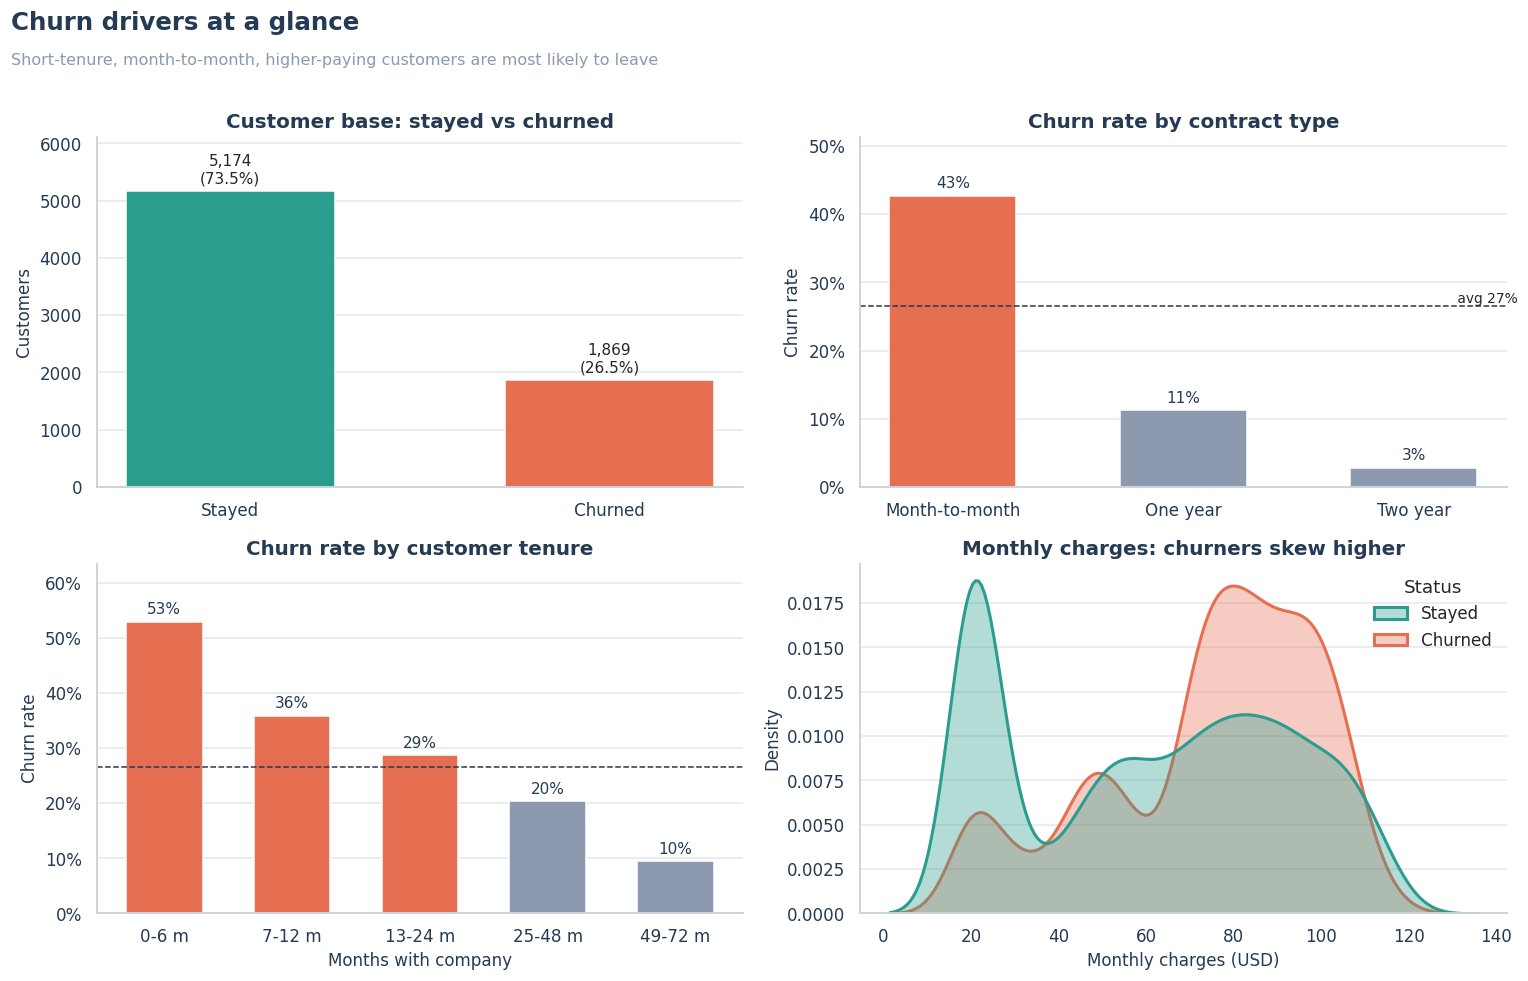

In [ ]:
# ============================================================================
# Exploratory analysis - who churns?
# ============================================================================
def churn_rate_by(col: str, data: pd.DataFrame = X) -> pd.Series:
    """Churn rate per category of ``col`` (sorted high -> low)."""
    return y.groupby(data[col]).mean().sort_values(ascending=False)


def annotate_bars(ax, fmt: str = "{:.0%}") -> None:
    for bars in ax.containers:
        ax.bar_label(bars, labels=[fmt.format(b.get_height()) for b in bars],
                     padding=3, fontsize=10, color=PAL["ink"])


tenure_band = pd.cut(X["tenure"], [-1, 6, 12, 24, 48, 72],
                     labels=["0-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"])
overall = y.mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Portfolio split
ax = axes[0, 0]
counts = y.value_counts().sort_index()
ax.bar(["Stayed", "Churned"], counts.values, color=[STAY, CHURN], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v + counts.max() * 0.015, f"{v:,}\n({v / len(y):.1%})", ha="center", va="bottom", fontsize=10)
ax.set(title="Customer base: stayed vs churned", ylabel="Customers",
       ylim=(0, counts.max() * 1.18))

# 2) Contract type
ax = axes[0, 1]
s = churn_rate_by("Contract")
ax.bar(s.index, s.values, color=[CHURN if v > overall else PAL["grey"] for v in s], width=0.55)
ax.axhline(overall, ls="--", color=PAL["ink"], lw=1)
ax.text(2.45, overall, f" avg {overall:.0%}", va="bottom", ha="right", fontsize=9)
annotate_bars(ax)
ax.set(title="Churn rate by contract type", ylabel="Churn rate", ylim=(0, s.max() * 1.2))
ax.yaxis.set_major_formatter(PercentFormatter(1))

# 3) Tenure band
ax = axes[1, 0]
s = y.groupby(tenure_band, observed=True).mean()
ax.bar(s.index.astype(str), s.values, color=[CHURN if v > overall else PAL["grey"] for v in s], width=0.6)
ax.axhline(overall, ls="--", color=PAL["ink"], lw=1)
annotate_bars(ax)
ax.set(title="Churn rate by customer tenure", xlabel="Months with company",
       ylabel="Churn rate", ylim=(0, s.max() * 1.2))
ax.yaxis.set_major_formatter(PercentFormatter(1))

# 4) Monthly charges
ax = axes[1, 1]
plot_df = pd.DataFrame({"MonthlyCharges": X["MonthlyCharges"],
                        "Status": y.map({0: "Stayed", 1: "Churned"})})
sns.kdeplot(data=plot_df, x="MonthlyCharges", hue="Status", fill=True, common_norm=False,
            palette={"Stayed": STAY, "Churned": CHURN}, alpha=0.35, linewidth=2,
            hue_order=["Stayed", "Churned"], ax=ax)
ax.set(title="Monthly charges: churners skew higher", xlabel=f"Monthly charges ({CURRENCY})",
       ylabel="Density")

headline(fig, "Churn drivers at a glance",
         "Short-tenure, month-to-month, higher-paying customers are most likely to leave")
plt.show()

## 5. Model comparison (cross-validated)

,ROC-AUC,ROC-AUC sd,PR-AUC,PR-AUC sd
Model,,,,
Logistic Regression,0.8457,0.0125,0.6598,0.0191
Random Forest,0.8466,0.0097,0.6606,0.0211
Gradient Boosting,0.8460,0.0088,0.6552,0.0232
Soft-Voting Ensemble,0.8502,0.0100,0.6668,0.0196


Selected model: Soft-Voting Ensemble


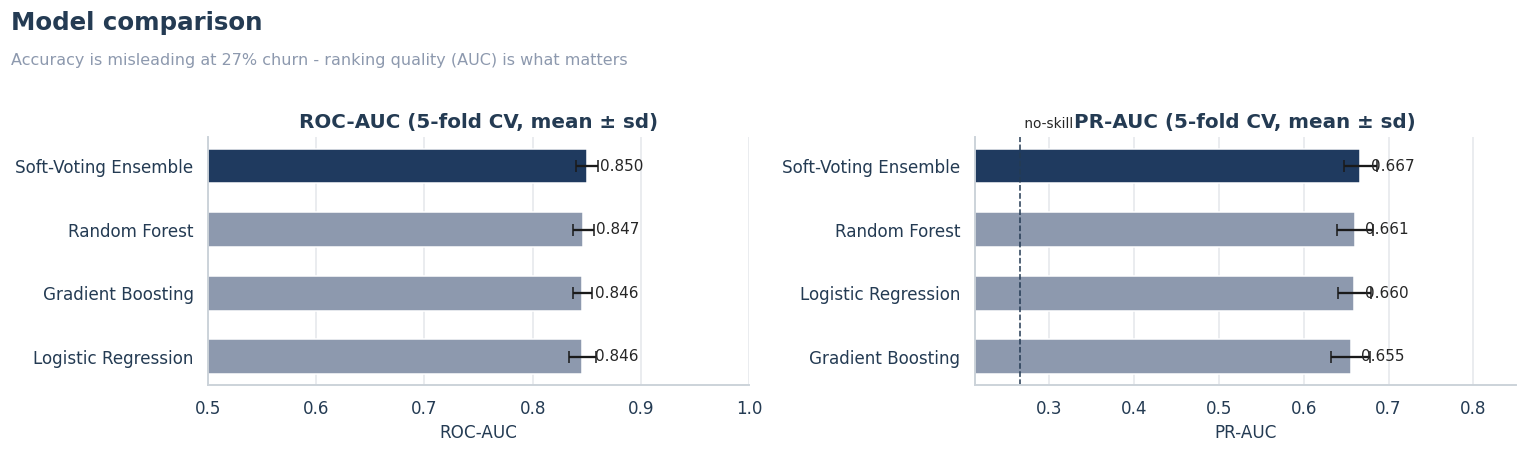

In [ ]:
# ============================================================================
# Honest model comparison: stratified hold-out + cross-validation on TRAIN only
# ============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=lib.RANDOM_STATE)
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=lib.RANDOM_STATE)

candidates = lib.get_candidate_models()
rows = []
for name, pipe in candidates.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, n_jobs=1,
                         scoring=["roc_auc", "average_precision"])
    rows.append({"Model": name,
                 "ROC-AUC": res["test_roc_auc"].mean(), "ROC-AUC sd": res["test_roc_auc"].std(),
                 "PR-AUC": res["test_average_precision"].mean(),
                 "PR-AUC sd": res["test_average_precision"].std()})
cv_results = pd.DataFrame(rows).set_index("Model")
best_name = cv_results["ROC-AUC"].idxmax()
display(cv_results.round(4))
print(f"Selected model: {best_name}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, metric in zip(axes, ["ROC-AUC", "PR-AUC"]):
    data = cv_results[metric].sort_values()
    colors = [PAL["navy"] if m == best_name else PAL["grey"] for m in data.index]
    ax.barh(data.index, data.values, xerr=cv_results.loc[data.index, f"{metric} sd"],
            color=colors, capsize=4, height=0.55)
    for i, v in enumerate(data.values):
        ax.text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=10)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set(title=f"{metric} (5-fold CV, mean ± sd)", xlabel=metric)
    ax.set_xlim(0.5 if metric == "ROC-AUC" else y_train.mean() * 0.8,
                1.0 if metric == "ROC-AUC" else 0.85)
axes[1].axvline(y_train.mean(), ls="--", color=PAL["ink"], lw=1)
axes[1].text(y_train.mean(), 3.55, " no-skill", fontsize=9, va="bottom")
headline(fig, "Model comparison", "Accuracy is misleading at 27% churn - ranking quality (AUC) is what matters")
plt.show()

## 6. Threshold tuning and test-set evaluation

Decision threshold (max-F1 on OOF): 0.350
roc_auc      0.846
pr_auc       0.654
precision    0.556
recall       0.711
f1           0.624
accuracy     0.773

Note: always predicting 'stayed' scores 73.5% accuracy, which is why accuracy alone was a misleading headline metric.


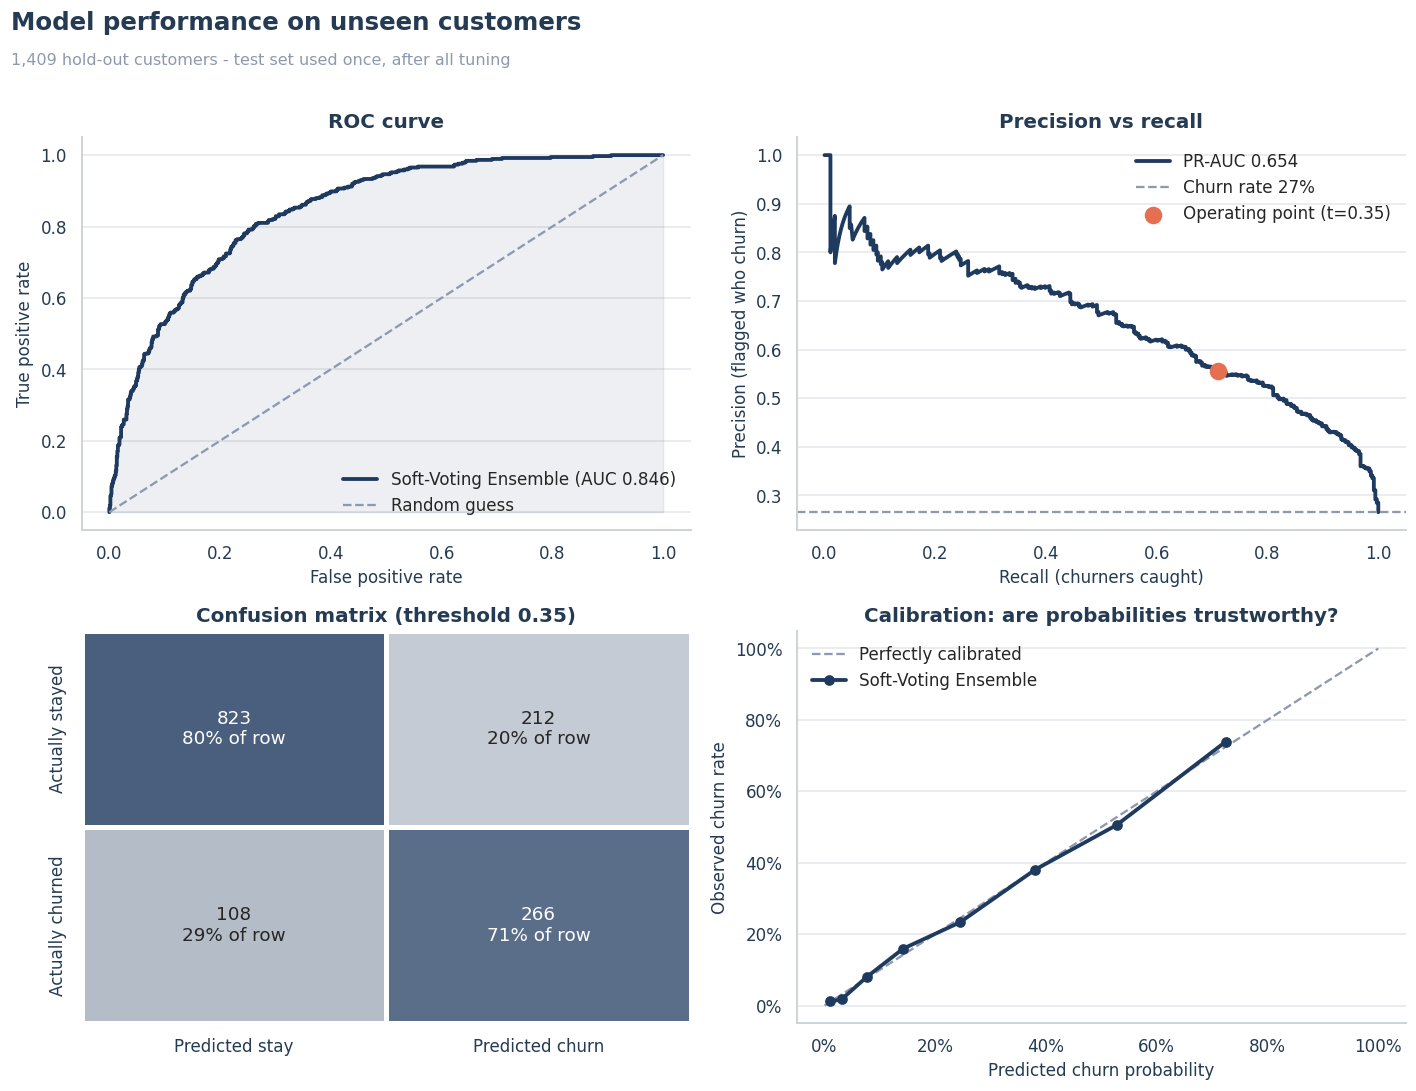

In [ ]:
# ============================================================================
# Threshold tuning (on out-of-fold predictions) and one-shot test evaluation
# ============================================================================
best_pipe = candidates[best_name]

# 1) Pick the decision threshold from OUT-OF-FOLD train predictions, so the test
#    set is never used for any tuning decision.
oof_proba = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
threshold = lib.best_f1_threshold(y_train, oof_proba)

# 2) Fit on the full training set, score the untouched test set once.
best_pipe.fit(X_train, y_train)
test_proba = best_pipe.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)

metrics = {
    "roc_auc": roc_auc_score(y_test, test_proba),
    "pr_auc": average_precision_score(y_test, test_proba),
    "precision": precision_score(y_test, test_pred),
    "recall": recall_score(y_test, test_pred),
    "f1": f1_score(y_test, test_pred),
    "accuracy": accuracy_score(y_test, test_pred),
}
baseline_acc = 1 - y_test.mean()
print(f"Decision threshold (max-F1 on OOF): {threshold:.3f}")
print(pd.Series(metrics).round(3).to_string())
print(f"\nNote: always predicting 'stayed' scores {baseline_acc:.1%} accuracy, which is why "
      "accuracy alone was a misleading headline metric.")

# ---- Evaluation dashboard ---------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

ax = axes[0, 0]                                   # ROC
fpr, tpr, _ = roc_curve(y_test, test_proba)
ax.plot(fpr, tpr, color=PAL["navy"], lw=2.5, label=f"{best_name} (AUC {metrics['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=PAL["grey"], label="Random guess")
ax.fill_between(fpr, tpr, alpha=0.08, color=PAL["navy"])
ax.set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
ax.legend(loc="lower right")

ax = axes[0, 1]                                   # Precision-recall
prec, rec, _ = precision_recall_curve(y_test, test_proba)
ax.plot(rec, prec, color=PAL["navy"], lw=2.5, label=f"PR-AUC {metrics['pr_auc']:.3f}")
ax.axhline(y_test.mean(), ls="--", color=PAL["grey"], label=f"Churn rate {y_test.mean():.0%}")
ax.scatter([metrics["recall"]], [metrics["precision"]], s=110, color=CHURN, zorder=5,
           label=f"Operating point (t={threshold:.2f})")
ax.set(title="Precision vs recall", xlabel="Recall (churners caught)",
       ylabel="Precision (flagged who churn)")
ax.legend(loc="upper right")

ax = axes[1, 0]                                   # Confusion matrix
cm = confusion_matrix(y_test, test_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True)
annot = np.array([[f"{cm[i, j]:,}\n{cm_pct[i, j]:.0%} of row" for j in range(2)] for i in range(2)])
sns.heatmap(cm_pct, annot=annot, fmt="", cmap=sns.light_palette(PAL["navy"], as_cmap=True),
            cbar=False, linewidths=2, linecolor="white", vmin=0, vmax=1, ax=ax,
            xticklabels=["Predicted stay", "Predicted churn"],
            yticklabels=["Actually stayed", "Actually churned"])
ax.set_title(f"Confusion matrix (threshold {threshold:.2f})")

ax = axes[1, 1]                                   # Calibration
frac_pos, mean_pred = calibration_curve(y_test, test_proba, n_bins=8, strategy="quantile")
ax.plot([0, 1], [0, 1], ls="--", color=PAL["grey"], label="Perfectly calibrated")
ax.plot(mean_pred, frac_pos, marker="o", color=PAL["navy"], lw=2.5, label=best_name)
ax.set(title="Calibration: are probabilities trustworthy?",
       xlabel="Predicted churn probability", ylabel="Observed churn rate")
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="upper left")

headline(fig, "Model performance on unseen customers",
         f"{len(y_test):,} hold-out customers - test set used once, after all tuning")
plt.show()

## 7. Explainability and targeting power

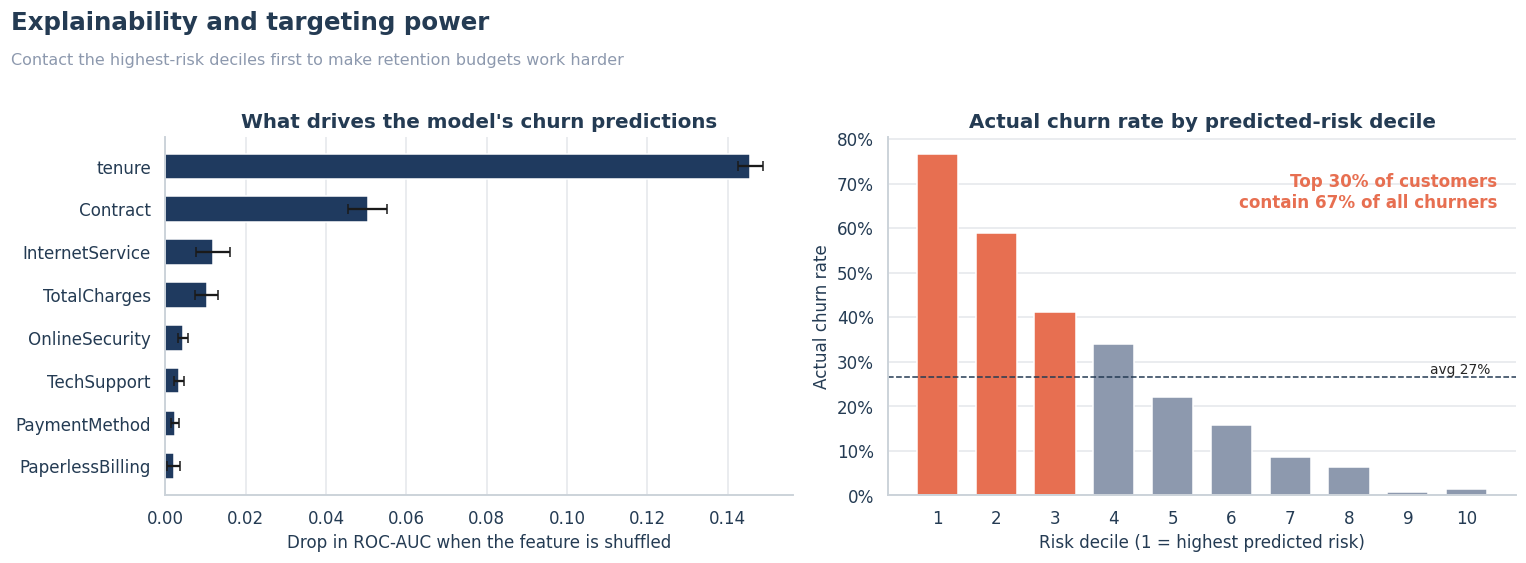

In [ ]:
# ============================================================================
# Explainability and business value
# ============================================================================
# Permutation importance on RAW columns (e.g. "Contract" as a whole) - far more
# interpretable than impurity importances of individual one-hot columns.
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=lib.RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                           index=X_test.columns).sort_values("mean", ascending=False))

# Decile lift: rank customers by predicted risk and compare with actual churn.
lift_df = pd.DataFrame({"p": test_proba, "y": y_test.values})
lift_df["decile"] = pd.qcut(lift_df["p"].rank(method="first", ascending=False), 10,
                            labels=range(1, 11))
decile_rate = lift_df.groupby("decile", observed=True)["y"].mean()
top3_capture = lift_df[lift_df["decile"].astype(int) <= 3]["y"].sum() / lift_df["y"].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

ax = axes[0]
top = importance.head(8).iloc[::-1]
ax.barh(top.index, top["mean"], xerr=top["std"], color=PAL["navy"], capsize=3, height=0.6)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set(title="What drives the model's churn predictions",
       xlabel="Drop in ROC-AUC when the feature is shuffled")

ax = axes[1]
ax.bar(decile_rate.index.astype(int), decile_rate.values,
       color=[CHURN if d <= 3 else PAL["grey"] for d in decile_rate.index.astype(int)], width=0.7)
ax.axhline(y_test.mean(), ls="--", color=PAL["ink"], lw=1)
ax.text(10.4, y_test.mean(), f"avg {y_test.mean():.0%}", va="bottom", ha="right", fontsize=9)
ax.set(title="Actual churn rate by predicted-risk decile", xlabel="Risk decile (1 = highest predicted risk)",
       ylabel="Actual churn rate", xticks=range(1, 11))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.text(0.97, 0.9, f"Top 30% of customers\ncontain {top3_capture:.0%} of all churners",
        transform=ax.transAxes, ha="right", va="top", fontsize=11, fontweight="bold", color=CHURN)

headline(fig, "Explainability and targeting power",
         "Contact the highest-risk deciles first to make retention budgets work harder")
plt.show()

## 8. Portfolio retention report

In [ ]:
# ============================================================================
# Data-driven portfolio report (every number below is computed, none hard-coded)
# ============================================================================
flagged = test_pred == 1
test_view = X_test.assign(p=test_proba, churned=y_test.values)

# Risk tiers - validated against what customers actually did.
medium_cut = threshold / 2
test_view["tier"] = np.select([test_proba >= threshold, test_proba >= medium_cut],
                              ["High", "Medium"], default="Low")
tiers = (test_view.groupby("tier")
         .agg(customers=("p", "size"), actual_churn_rate=("churned", "mean"),
              monthly_revenue=("MonthlyCharges", "sum"))
         .reindex(["High", "Medium", "Low"]))

# Segment hot-spots on the full customer base (descriptive, min. 200 customers).
seg_frame = X.assign(**{"Tenure band": tenure_band.astype(str)})
SEGMENT_COLS = ["Contract", "InternetService", "PaymentMethod", "Tenure band", "PaperlessBilling"]
seg_rows = []
for col in SEGMENT_COLS:
    grp = y.groupby(seg_frame[col]).agg(["mean", "size"])
    for value, r in grp.iterrows():
        if r["size"] >= 200:
            seg_rows.append({"feature": col, "segment": value, "customers": int(r["size"]),
                             "churn_rate": float(r["mean"]), "lift": float(r["mean"] / y.mean())})
segments = (pd.DataFrame(seg_rows).sort_values("lift", ascending=False).head(5)
            .reset_index(drop=True))

report = {
    "n_test": int(len(y_test)),
    "actual_churn_rate": float(y_test.mean()),
    "expected_churn_rate": float(test_proba.mean()),
    "n_flagged": int(flagged.sum()),
    "flagged_share": float(flagged.mean()),
    "flagged_monthly_revenue": float(X_test.loc[flagged, "MonthlyCharges"].sum()),
    "expected_monthly_revenue_lost": float((test_proba * X_test["MonthlyCharges"]).sum()),
}

line = "=" * 64
print(line + "\nPORTFOLIO RETENTION REPORT (hold-out sample)\n" + line)
print(f"Actual churn rate .................. {report['actual_churn_rate']:.1%}")
print(f"Model-expected churn rate .......... {report['expected_churn_rate']:.1%}  (mean predicted probability)")
print(f"Customers flagged high-risk ........ {report['n_flagged']:,} ({report['flagged_share']:.1%} of {report['n_test']:,})")
print(f"  of which precision / recall ...... {metrics['precision']:.0%} / {metrics['recall']:.0%}")
print(f"Monthly revenue of flagged ......... {report['flagged_monthly_revenue']:,.0f} {CURRENCY}")
print(f"Expected monthly revenue at risk ... {report['expected_monthly_revenue_lost']:,.0f} {CURRENCY}")
print("\nRisk tiers (do the tiers separate real behaviour?):")
display(tiers.style.format({"customers": "{:,}", "actual_churn_rate": "{:.1%}",
                            "monthly_revenue": "{:,.0f}"}))
print("Highest-risk segments (full base):")
display(segments.style.format({"customers": "{:,}", "churn_rate": "{:.1%}", "lift": "{:.2f}x"}))

# Strategy playbook - the ACTIONS are business assumptions to validate; the
# SEGMENTS they attach to are computed above.
PLAYBOOK = {
    "Contract": "Offer incentives to move month-to-month customers onto 12/24-month plans.",
    "PaymentMethod": "Promote automatic payment (bank/card) with a small bill credit.",
    "InternetService": "Review pricing and service quality for this product line.",
    "Tenure band": "Run a structured onboarding / first-90-days engagement programme.",
    "PaperlessBilling": "Pair e-billing with proactive usage and value reminders.",
}
print("Recommended focus areas:")
for i, r in segments.head(3).iterrows():
    print(f"  {i + 1}. {r['feature']} = {r['segment']}: {r['churn_rate']:.0%} churn "
          f"({r['lift']:.1f}x average, {r['customers']:,} customers)\n"
          f"     -> {PLAYBOOK[r['feature']]}")

PORTFOLIO RETENTION REPORT (hold-out sample)
Actual churn rate .................. 26.5%
Model-expected churn rate .......... 26.7%  (mean predicted probability)
Customers flagged high-risk ........ 478 (33.9% of 1,409)
  of which precision / recall ...... 56% / 71%
Monthly revenue of flagged ......... 36,482 USD
Expected monthly revenue at risk ... 27,850 USD

Risk tiers (do the tiers separate real behaviour?):


,customers,actual_churn_rate,monthly_revenue
tier,,,
High,478,55.6%,"36,482"
Medium,246,26.0%,"16,735"
Low,685,6.4%,"37,085"


Highest-risk segments (full base):


,feature,segment,customers,churn_rate,lift
0,Tenure band,0-6 m,"1,481",52.9%,1.99x
1,PaymentMethod,Electronic check,"2,365",45.3%,1.71x
2,Contract,Month-to-month,"3,875",42.7%,1.61x
3,InternetService,Fiber optic,"3,096",41.9%,1.58x
4,Tenure band,7-12 m,705,35.9%,1.35x


Recommended focus areas:
  1. Tenure band = 0-6 m: 53% churn (2.0x average, 1,481 customers)
     -> Run a structured onboarding / first-90-days engagement programme.
  2. PaymentMethod = Electronic check: 45% churn (1.7x average, 2,365 customers)
     -> Promote automatic payment (bank/card) with a small bill credit.
  3. Contract = Month-to-month: 43% churn (1.6x average, 3,875 customers)
     -> Offer incentives to move month-to-month customers onto 12/24-month plans.


## 9. Save deployable artifacts

In [ ]:
# ============================================================================
# Persist deployable artifacts: ONE pipeline (raw input -> probability) + metadata
# ============================================================================
# Deployment model: same hyper-parameters, refit on 100% of the data.
# (Metrics above come from the hold-out fit; they are the honest estimate.)
final_model = lib.get_candidate_models()[best_name].fit(X, y)

metadata = {
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "model_name": best_name,
    "threshold": threshold,
    "medium_threshold": medium_cut,
    "currency": CURRENCY,
    "data_source": "IBM Telco Customer Churn (public sample dataset)" if DATA_SOURCE == lib.DATA_URL else str(DATA_SOURCE),
    "holdout_metrics": metrics,
    "report": report,
    "tiers": tiers.reset_index().to_dict("records"),
    "segments": segments.to_dict("records"),
    "playbook": PLAYBOOK,
    "importance": importance["mean"].head(10).round(5).to_dict(),
    "categories": {c: sorted(X[c].unique().tolist()) for c in lib.CATEGORICAL},
    "numeric_ranges": {c: {"min": float(X[c].min()), "max": float(X[c].max()),
                           "median": float(X[c].median())} for c in lib.RAW_NUMERIC},
    "defaults": {c: X[c].mode().iat[0] for c in lib.CATEGORICAL},
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "pandas": pd.__version__},
}
joblib.dump(final_model, ARTIFACT_DIR / "churn_pipeline.joblib")
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str))

# Demo file for the dashboard's "Use sample" button (and the downloadable template).
demo = X.sample(1500, random_state=lib.RANDOM_STATE).copy()
demo.insert(0, "customer_id", [f"C-{i:04d}" for i in range(1, len(demo) + 1)])
demo["Churn"] = y.loc[demo.index].map({1: "Yes", 0: "No"})
demo.to_csv(ARTIFACT_DIR / "demo_customers.csv", index=False)

# Round-trip check: reload from disk and confirm identical predictions.
reloaded = joblib.load(ARTIFACT_DIR / "churn_pipeline.joblib")
assert np.allclose(reloaded.predict_proba(X.head(50)), final_model.predict_proba(X.head(50)))
print(f"Saved to ./{ARTIFACT_DIR}/ : churn_pipeline.joblib, metadata.json, demo_customers.csv (reload check passed)")

Saved to ./artifacts/ : churn_pipeline.joblib, metadata.json, demo_customers.csv (reload check passed)


## 10. Dashboard app
Three files: the analysis engine, the visual theme, and the app itself.

In [ ]:
%%writefile churn_engine.py
"""Analysis engine behind the "Analyze your data" page.

Pure functions (no Streamlit) so every step can be unit-tested:
    read_table -> auto_map -> prepare -> analyze -> campaign_curve / recommend
"""
from __future__ import annotations

import io
import re
from dataclasses import dataclass, field
from typing import Dict, List, Optional

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

import churn_lib as lib

NOT_PROVIDED = "— not provided —"
ID_FIELD, TARGET_FIELD = "customer_id", "churn_label"
REQUIRED = ["tenure", "MonthlyCharges"]
MAX_ROWS = 50_000
MIN_ROWS_RETRAIN, MIN_CLASS_RETRAIN = 500, 50

# Header names we recognise automatically (compared after stripping punctuation/case).
ALIASES: Dict[str, List[str]] = {
    "tenure": ["tenuremonths", "monthswithcompany", "customertenure", "months",
               "subscriptionmonths", "customerage", "accountage"],
    "MonthlyCharges": ["monthlybill", "monthlyfee", "monthlyrevenue", "mrr", "arpu",
                       "monthlyamount", "monthlycost", "monthlyspend"],
    "TotalCharges": ["totalbilled", "totalspend", "lifetimevalue", "totalrevenue", "totalamount"],
    "gender": ["sex"],
    "SeniorCitizen": ["senior", "issenior", "seniorcitizen"],
    "InternetService": ["internet", "internetplan", "internettype"],
    "PaymentMethod": ["paymenttype", "paymentmode", "billingmethod"],
    "Contract": ["contracttype", "plantype", "contractterm", "plan"],
    "PaperlessBilling": ["paperless", "ebilling"],
    ID_FIELD: ["customerid", "id", "customer", "accountid", "accountnumber", "subscriberid", "msisdn"],
    TARGET_FIELD: ["churn", "churned", "ischurned", "attrition", "left", "exited", "churnlabel"],
}
POS = {"yes", "y", "true", "t", "1", "1.0", "churned", "churn", "left", "cancelled", "canceled"}
NEG = {"no", "n", "false", "f", "0", "0.0", "stayed", "active", "retained"}

SEGMENT_FEATURES = ["Contract", "PaymentMethod", "InternetService", "Tenure band",
                    "PaperlessBilling", "TechSupport", "OnlineSecurity"]
PLAYBOOK = {
    "Contract": "Offer incentives to move month-to-month customers onto 12/24-month plans.",
    "PaymentMethod": "Promote automatic payment (bank/card) with a small bill credit.",
    "InternetService": "Review pricing and service quality for this product line.",
    "Tenure band": "Run a structured onboarding / first-90-days engagement programme.",
    "PaperlessBilling": "Pair e-billing with proactive usage and value reminders.",
    "TechSupport": "Bundle a free tech-support trial for customers who lack it.",
    "OnlineSecurity": "Bundle a free online-security trial for customers who lack it.",
}
TENURE_BINS = [-1, 6, 12, 24, 48, 10_000]
TENURE_LABELS = ["0-6 m", "7-12 m", "13-24 m", "25-48 m", "49+ m"]


def _norm(name: str) -> str:
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


# --------------------------------------------------------------------------- #
# Reading + column matching
# --------------------------------------------------------------------------- #
def read_table(file, name: str = "") -> pd.DataFrame:
    """Read an uploaded CSV / Excel file into a DataFrame."""
    name = (name or getattr(file, "name", "")).lower()
    if name.endswith((".xlsx", ".xls")):
        df = pd.read_excel(file)
    else:
        raw = file.read() if hasattr(file, "read") else file
        raw = raw.encode() if isinstance(raw, str) else raw
        df = None
        for enc in ("utf-8-sig", "latin-1"):
            try:
                df = pd.read_csv(io.BytesIO(raw), encoding=enc, sep=None, engine="python")
                break
            except UnicodeDecodeError:
                continue
        if df is None:
            raise ValueError("Could not read the file - please save it as UTF-8 CSV.")
    df.columns = [str(c).strip() for c in df.columns]
    if df.empty:
        raise ValueError("The file has no rows.")
    return df


def auto_map(columns: List[str]) -> Dict[str, Optional[str]]:
    """Guess which uploaded column plays which role (user can override)."""
    lookup = {_norm(c): c for c in columns}
    used, mapping = set(), {}
    for field_name in [*lib.RAW_FEATURES, ID_FIELD, TARGET_FIELD]:
        keys = [_norm(field_name), *ALIASES.get(field_name, [])]
        hit = next((lookup[k] for k in keys if k in lookup and lookup[k] not in used), None)
        mapping[field_name] = hit
        if hit:
            used.add(hit)
    return mapping


# --------------------------------------------------------------------------- #
# Cleaning
# --------------------------------------------------------------------------- #
def _canon_categorical(series: pd.Series, allowed: List[str]):
    """Map free-text values onto the categories the model knows (case-insensitive,
    Y/N/True/False/1/0 understood). Returns (canonical series, recognised share)."""
    allowed_l = {a.lower(): a for a in allowed}
    binary = set(allowed_l) <= {"yes", "no", "no internet service", "no phone service"}
    low = series.astype("string").str.strip().str.lower()

    def fix(v):
        if binary and v in {"y", "true", "t", "1", "1.0"}:
            return "yes"
        if binary and v in {"n", "false", "f", "0", "0.0"}:
            return "no"
        return v

    mapped = low.map(fix, na_action="ignore").map(allowed_l, na_action="ignore")
    share = float(mapped.notna().sum() / max(low.notna().sum(), 1))
    return mapped.astype(object), share


def parse_target(series: pd.Series) -> pd.Series:
    low = series.astype("string").str.strip().str.lower()
    return low.map(lambda v: 1 if v in POS else 0 if v in NEG else np.nan,
                   na_action="ignore").astype("float64")


@dataclass
class Prepared:
    X: pd.DataFrame
    mrr: pd.Series
    ids: pd.Series
    y: Optional[pd.Series]
    provided: List[str]
    notes: List[str] = field(default_factory=list)
    n_dropped: int = 0

    @property
    def completeness(self) -> float:
        return len(self.provided) / len(lib.RAW_FEATURES)


def prepare(df: pd.DataFrame, mapping: Dict[str, Optional[str]], meta: dict) -> Prepared:
    """Turn an arbitrary customer table into the 19-column frame the model expects."""
    if len(df) > MAX_ROWS:
        raise ValueError(f"Please upload at most {MAX_ROWS:,} rows (file has {len(df):,}).")
    for req in REQUIRED:
        if not mapping.get(req):
            raise ValueError(f"A column for '{req}' is required - map one in 'Review column matching'.")

    notes: List[str] = []
    X = pd.DataFrame(index=df.index)
    for col in lib.RAW_NUMERIC:
        src = mapping.get(col)
        X[col] = pd.to_numeric(df[src], errors="coerce") if src else np.nan

    valid = X[REQUIRED].notna().all(axis=1) & (X["tenure"] >= 0) & (X["MonthlyCharges"] >= 0)
    if valid.mean() < 0.5:
        raise ValueError("More than half the rows have an unreadable tenure or monthly charge - "
                         "check the column mapping.")
    n_dropped = int((~valid).sum())
    if n_dropped:
        notes.append(f"{n_dropped:,} rows were skipped because tenure or monthly charge was "
                     "missing or negative.")

    provided = [c for c in REQUIRED]
    if mapping.get("TotalCharges"):
        provided.append("TotalCharges")
    total_missing = X["TotalCharges"].isna()
    X.loc[total_missing, "TotalCharges"] = X["tenure"] * X["MonthlyCharges"]
    if not mapping.get("TotalCharges"):
        notes.append("No total-charges column: estimated as tenure x monthly charge.")

    defaults, cats = meta["defaults"], meta["categories"]
    for col in lib.CATEGORICAL:
        src = mapping.get(col)
        if src:
            canon, share = _canon_categorical(df[src], cats[col])
            if share >= 0.5:
                provided.append(col)
                X[col] = canon.fillna(defaults[col])
                if share < 0.98:
                    notes.append(f"'{src}': {1 - share:.0%} of values were not recognised and "
                                 f"were set to '{defaults[col]}'.")
                continue
            notes.append(f"'{src}' looks different from what the model expects "
                         f"({', '.join(cats[col][:3])}...) - ignored.")
        X[col] = defaults[col]

    # Keep service flags logically consistent with how the training data encodes them.
    if "InternetService" in provided:
        no_net = X["InternetService"] == "No"
        for col in lib.ADDON_SERVICES:
            X.loc[no_net, col] = "No internet service"
    if "PhoneService" in provided:
        X.loc[X["PhoneService"] == "No", "MultipleLines"] = "No phone service"

    y = None
    if mapping.get(TARGET_FIELD):
        parsed = parse_target(df[mapping[TARGET_FIELD]])
        if parsed.loc[valid].notna().mean() >= 0.95:
            y = parsed
        else:
            notes.append("The churn column could not be read as Yes/No - analysing without it.")

    ids = (df[mapping[ID_FIELD]].astype(str) if mapping.get(ID_FIELD)
           else pd.Series([f"Row {i + 1}" for i in range(len(df))], index=df.index))

    keep = valid.copy()
    if y is not None:
        keep &= y.notna()
        n_dropped = int((~keep).sum())
    X = X.loc[keep, lib.RAW_FEATURES].reset_index(drop=True)
    out_y = y.loc[keep].astype(int).reset_index(drop=True) if y is not None else None
    return Prepared(X, X["MonthlyCharges"].copy(), ids.loc[keep].reset_index(drop=True),
                    out_y, provided, notes, n_dropped)


# --------------------------------------------------------------------------- #
# Modelling
# --------------------------------------------------------------------------- #
@dataclass
class Analysis:
    scored: pd.DataFrame
    threshold: float
    medium: float
    mode: str                                   # "pretrained" | "retrained"
    metrics: Optional[Dict[str, float]]
    importance: Optional[pd.Series]
    segments: pd.DataFrame
    prepared: Prepared


def can_retrain(prep: Prepared) -> bool:
    if prep.y is None or len(prep.y) < MIN_ROWS_RETRAIN:
        return False
    return int(prep.y.sum()) >= MIN_CLASS_RETRAIN and int((1 - prep.y).sum()) >= MIN_CLASS_RETRAIN


def suggested_action(X: pd.DataFrame, tier: pd.Series, provided: List[str]) -> pd.Series:
    has = lambda c: c in provided
    false = pd.Series(False, index=X.index)
    rules = [
        (X["tenure"] <= 6, "Onboarding call + early-life offer"),
        ((X["Contract"] == "Month-to-month") if has("Contract") else false,
         "Offer a 12/24-month plan with incentive"),
        ((~X["PaymentMethod"].isin(lib.AUTOPAY_METHODS)) if has("PaymentMethod") else false,
         "Promote autopay with a bill credit"),
        (((X["InternetService"] != "No") & (X["TechSupport"] == "No")) if has("TechSupport") and has("InternetService") else false,
         "Offer a free tech-support trial"),
    ]
    action = np.select([c for c, _ in rules], [a for _, a in rules], default="Proactive check-in call")
    return pd.Series(np.where(tier == "Low", "Monitor", action), index=X.index)


def segment_table(prep: Prepared, p: np.ndarray) -> pd.DataFrame:
    frame = prep.X.copy()
    frame["Tenure band"] = pd.cut(frame["tenure"], TENURE_BINS, labels=TENURE_LABELS).astype(str)
    frame["p"] = p
    if prep.y is not None:
        frame["actual"] = prep.y.values
    overall, min_size = p.mean(), max(30, int(0.03 * len(frame)))
    rows = []
    for feat in SEGMENT_FEATURES:
        if feat != "Tenure band" and feat not in prep.provided:
            continue
        for value, g in frame.groupby(feat, observed=True):
            if len(g) >= min_size:
                rows.append({"feature": feat, "segment": str(value), "customers": len(g),
                             "avg_risk": g["p"].mean(), "lift": g["p"].mean() / overall,
                             "actual_rate": g["actual"].mean() if "actual" in g else np.nan})
    return pd.DataFrame(rows)


def analyze(prep: Prepared, meta: dict, pretrained, retrain: bool) -> Analysis:
    X, y = prep.X, prep.y
    importance = None
    if retrain and can_retrain(prep):
        pipe = lib.get_candidate_models()["Soft-Voting Ensemble"]
        cv = StratifiedKFold(5, shuffle=True, random_state=lib.RANDOM_STATE)
        p = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]  # honest: every row scored out-of-fold
        threshold, mode = lib.best_f1_threshold(y, p), "retrained"
        fitted = clone(pipe).fit(X, y)
        sample = X.sample(min(len(X), 1500), random_state=lib.RANDOM_STATE)
        perm = permutation_importance(fitted, sample, y.loc[sample.index], scoring="roc_auc",
                                      n_repeats=3, random_state=lib.RANDOM_STATE, n_jobs=-1)
        importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
    else:
        p = pretrained.predict_proba(X)[:, 1]
        threshold, mode = meta["threshold"], "pretrained"

    medium = threshold / 2
    tier = pd.Series(np.select([p >= threshold, p >= medium], ["High", "Medium"], "Low"))
    metrics = None
    if y is not None:
        flag = (p >= threshold).astype(int)
        metrics = {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
                   "precision": precision_score(y, flag, zero_division=0),
                   "recall": recall_score(y, flag), "f1": f1_score(y, flag),
                   "actual_rate": float(y.mean())}
    scored = pd.DataFrame({
        "customer": prep.ids.values, "risk": p, "tier": tier.values,
        "monthly_revenue": prep.mrr.values, "value_at_risk": p * prep.mrr.values,
        "tenure": X["tenure"].values,
        "action": suggested_action(X, tier, prep.provided).values})
    if y is not None:
        scored["actually_churned"] = y.values
    scored = scored.sort_values("value_at_risk", ascending=False).reset_index(drop=True)
    return Analysis(scored, threshold, medium, mode, metrics, importance,
                    segment_table(prep, p), prep)


# --------------------------------------------------------------------------- #
# Projections + recommendations
# --------------------------------------------------------------------------- #
def campaign_curve(scored: pd.DataFrame, success_rate: float, cost_per_contact: float,
                   months_value: int) -> pd.DataFrame:
    """Net benefit of contacting the top-k customers, ranked by value at risk.

    benefit_i = P(churn_i) x save-rate x monthly revenue_i x months of revenue kept
    cost      = contacts x cost per contact
    (expected values; they rely on the three editable assumptions)
    """
    ev = scored["value_at_risk"].to_numpy()          # already sorted high -> low
    benefit = np.cumsum(ev) * success_rate * months_value
    k = np.arange(1, len(ev) + 1)
    cost = k * cost_per_contact
    return pd.DataFrame({"contacted": k, "share": k / len(ev), "benefit": benefit,
                         "cost": cost, "net": benefit - cost})


def best_campaign(curve: pd.DataFrame) -> pd.Series:
    row = curve.loc[curve["net"].idxmax()]
    return row if row["net"] > 0 else curve.iloc[0] * 0


def recommend(an: Analysis, cur: str, success_rate: float, cost: float, months: int) -> List[dict]:
    recs, sc = [], an.scored
    curve = campaign_curve(sc, success_rate, cost, months)
    best = best_campaign(curve)
    if best["contacted"] > 0:
        roi = best["net"] / best["cost"] if best["cost"] else 0
        recs.append({"title": f"Run a retention campaign on the top {int(best['contacted']):,} customers",
                     "detail": (f"These {best['share']:.0%} of customers, ranked by revenue at risk, are the "
                                f"most profitable to contact. Under your assumptions the campaign returns about "
                                f"{best['net']:,.0f} {cur} net (ROI {roi:.1f}x)."), "kind": "campaign"})
    else:
        recs.append({"title": "A broad campaign does not pay back under current assumptions",
                     "detail": "Lower the contact cost, raise the expected save rate, or target only the highest-value customers.",
                     "kind": "campaign"})
    seg = an.segments
    if not seg.empty:
        seg = seg[(seg["lift"] > 1.15) & ~(seg["feature"].isin(["TechSupport", "OnlineSecurity"]) & (seg["segment"] != "No"))]
        for _, r in seg.sort_values("lift", ascending=False).head(3).iterrows():
            recs.append({"title": f"Focus on {r['feature']}: {r['segment']}",
                         "detail": (f"Predicted churn {r['avg_risk']:.0%} ({r['lift']:.1f}x your average) across "
                                    f"{int(r['customers']):,} customers. {PLAYBOOK[r['feature']]}"), "kind": "segment"})
    if an.mode == "pretrained":
        txt = "Results come from a model trained on public sample data, so treat them as indicative. "
        if an.metrics and an.metrics["roc_auc"] < 0.65:
            txt += (f"On your history it ranks customers poorly (AUC {an.metrics['roc_auc']:.2f}); "
                    "train on your own data for reliable results.")
        elif an.metrics:
            txt += f"On your history it reaches AUC {an.metrics['roc_auc']:.2f}."
        else:
            txt += "Upload past customers with a Churn column to train a model on your own data."
        recs.append({"title": "Improve accuracy with your own history", "detail": txt, "kind": "data"})
    if an.prepared.completeness < 0.6:
        recs.append({"title": "Add more customer fields for sharper insights",
                     "detail": (f"Only {len(an.prepared.provided)} of {len(lib.RAW_FEATURES)} fields were found. "
                                "Contract type, payment method and services are the biggest drivers."), "kind": "data"})
    return recs

Overwriting churn_engine.py


In [ ]:
from pathlib import Path

Path(".streamlit").mkdir(exist_ok=True)
Path(".streamlit/config.toml").write_text("""
[theme]
base = "light"
primaryColor = "#2A9D8F"
backgroundColor = "#F6F8FB"
secondaryBackgroundColor = "#FFFFFF"
textColor = "#243B53"
font = "sans serif"

[server]
maxUploadSize = 50

[browser]
gatherUsageStats = false
""".lstrip())
print("Theme config written")

Theme config written


In [ ]:
%%writefile app.py
"""Customer Retention Intelligence - Streamlit app.

Pages: Home (what the platform does) | Analyze your data (upload -> Analyze ->
findings, projections, recommendations) | Single customer (what-if scoring).
All numbers are computed from the model / uploaded data - nothing is mocked.
"""
import json
from pathlib import Path

import altair as alt
import joblib
import numpy as np
import pandas as pd
import streamlit as st

import churn_engine as eng
import churn_lib as lib
from churn_lib import ADDON_SERVICES, AUTOPAY_METHODS

ART = Path("artifacts")
NAVY, TEAL, CORAL, GOLD, GREY, INK = "#1F3A5F", "#2A9D8F", "#E76F51", "#E9C46A", "#8D99AE", "#243B53"
HOME, ANALYZE, SINGLE = "🏠  Home", "📂  Analyze your data", "👤  Single customer"
TIER_COLORS = alt.Scale(domain=["High", "Medium", "Low"], range=[CORAL, GOLD, TEAL])

st.set_page_config(page_title="Customer Retention Intelligence", page_icon="🎯",
                   layout="wide", initial_sidebar_state="expanded")

st.markdown("""<style>
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');
html, body, [class*="css"], .stMarkdown { font-family: 'Inter', sans-serif; }
#MainMenu, footer, [data-testid="stToolbar"], .stAppDeployButton { visibility: hidden; display: none; }
header[data-testid="stHeader"] { background: transparent; }
.block-container { padding-top: 1.6rem; max-width: 1240px; }
[data-testid="stSidebar"] { background: #FFFFFF; border-right: 1px solid #E4E7EB; }
.brand { font-weight: 800; font-size: 1.15rem; color: #1F3A5F; letter-spacing: -.01em; }
.brand span { color: #2A9D8F; }
.hero { background: linear-gradient(135deg, #1F3A5F 0%, #24668A 55%, #2A9D8F 100%);
        padding: 2.6rem 2.8rem; border-radius: 22px; color: #fff; margin-bottom: 1.4rem; }
.hero h1 { font-size: 2.5rem; font-weight: 800; line-height: 1.15; margin: .2rem 0 .8rem; color: #fff; letter-spacing: -.02em; }
.hero p { font-size: 1.12rem; opacity: .93; max-width: 780px; margin: 0; line-height: 1.55; }
.badge { display: inline-block; background: rgba(255,255,255,.17); padding: .28rem .85rem;
         border-radius: 999px; font-size: .8rem; font-weight: 600; letter-spacing: .02em; }
.card { background: #fff; border: 1px solid #E4E7EB; border-radius: 18px; padding: 1.3rem 1.4rem;
        box-shadow: 0 2px 10px rgba(31,58,95,.05); min-height: 205px; }
.card .ico { font-size: 1.7rem; }
.card h4 { margin: .45rem 0 .3rem; color: #1F3A5F; font-size: 1.05rem; font-weight: 700; }
.card p { margin: 0; color: #52606D; font-size: .93rem; line-height: 1.5; }
.step-n { display: inline-flex; width: 30px; height: 30px; border-radius: 50%; background: #2A9D8F;
          color: #fff; font-weight: 700; align-items: center; justify-content: center; margin-bottom: .4rem; }
.kpi { background: #fff; border: 1px solid #E4E7EB; border-radius: 16px; padding: 1rem 1.15rem;
       box-shadow: 0 2px 10px rgba(31,58,95,.05); }
.kpi .l { font-size: .76rem; font-weight: 600; text-transform: uppercase; letter-spacing: .05em; color: #7B8794; }
.kpi .v { font-size: 1.5rem; font-weight: 800; color: #1F3A5F; line-height: 1.25; }
.kpi .s { font-size: .82rem; color: #7B8794; }
.kpi.bad .v { color: #E76F51; } .kpi.good .v { color: #2A9D8F; }
.headline { background: #EAF6F4; border-left: 6px solid #2A9D8F; border-radius: 12px;
            padding: 1.1rem 1.3rem; font-size: 1.08rem; color: #1F3A5F; line-height: 1.55; margin: .6rem 0 1.1rem; }
.rec { background: #fff; border: 1px solid #E4E7EB; border-left: 5px solid #2A9D8F; border-radius: 12px;
       padding: 1rem 1.2rem; margin-bottom: .75rem; }
.rec.campaign { border-left-color: #E76F51; } .rec.data { border-left-color: #E9C46A; }
.rec b { color: #1F3A5F; font-size: 1.02rem; } .rec div { color: #52606D; font-size: .94rem; margin-top: .25rem; }
.note { color: #7B8794; font-size: .85rem; }
div[data-testid="stTabs"] button { font-weight: 600; }
.stButton > button[kind="primary"] { border-radius: 12px; font-weight: 700; padding: .65rem 1.4rem; }
</style>""", unsafe_allow_html=True)


# ----------------------------------------------------------------------------- helpers
@st.cache_resource
def load_artifacts():
    return (joblib.load(ART / "churn_pipeline.joblib"),
            json.loads((ART / "metadata.json").read_text()))


try:
    MODEL, META = load_artifacts()
except FileNotFoundError:
    st.error("Model files not found. Run the notebook's training cells first "
             "(they create ./artifacts/churn_pipeline.joblib and metadata.json).")
    st.stop()


def html(s: str) -> None:
    st.markdown("\n".join(line.strip() for line in s.strip().splitlines()), unsafe_allow_html=True)


def kpi(label, value, sub="", tone=""):
    html(f'<div class="kpi {tone}"><div class="l">{label}</div><div class="v">{value}</div>'
         f'<div class="s">{sub}</div></div>')


def card(icon, title, text):
    html(f'<div class="card"><div class="ico">{icon}</div><h4>{title}</h4><p>{text}</p></div>')


def money(v, cur): return f"{v:,.0f} {cur}"


def chart_style(ch, height=280):
    return (ch.properties(height=height)
            .configure_axis(labelColor=INK, titleColor=INK, gridColor="#E4E7EB", domainColor="#CBD2D9")
            .configure_view(strokeWidth=0).configure_legend(labelColor=INK, titleColor=INK))


def go(page):  # callback used by call-to-action buttons
    st.session_state["nav"] = page


# ----------------------------------------------------------------------------- sidebar
with st.sidebar:
    html('<div class="brand">🎯 Retention <span>Intelligence</span></div>')
    st.caption("Know who will leave, why, and what to do about it.")
    page = st.radio("Navigate", [HOME, ANALYZE, SINGLE], key="nav", label_visibility="collapsed")
    st.divider()
    CUR = st.selectbox("Currency label", ["BHD", "USD", "SAR", "AED", "KWD", "EUR", "GBP"],
                       help="Label only - amounts are shown exactly as they appear in your file.")
    st.caption(f"Built-in model: {META['model_name']}, trained {META['trained_at'][:10]} "
               f"on {META['data_source']}.")


# ----------------------------------------------------------------------------- HOME
def page_home():
    m = META["holdout_metrics"]
    html("""<div class="hero"><span class="badge">CUSTOMER RETENTION INTELLIGENCE</span>
    <h1>Keep the customers you can't afford to lose.</h1>
    <p>Upload your customer data and get, in minutes, a clear view of who is likely to leave,
    how much revenue that puts at risk, and which retention actions pay back - all in plain language,
    ready for your leadership team.</p></div>""")
    a, b, _ = st.columns([1.2, 1.2, 3])
    a.button("🚀 Analyze my data", type="primary", on_click=go, args=(ANALYZE,), width="stretch")
    b.button("✨ See a live demo", on_click=lambda: (go(ANALYZE), st.session_state.update(want_demo=True)),
             width="stretch")

    st.markdown("### How it works")
    c = st.columns(3)
    with c[0]:
        html('<div class="card"><div class="step-n">1</div><h4>Upload</h4><p>Drop in a CSV or Excel file of your customers. '
             'Columns are matched automatically - no data-science setup.</p></div>')
    with c[1]:
        html('<div class="card"><div class="step-n">2</div><h4>Analyze</h4><p>One click. The platform learns from your history '
             '(or uses a built-in model) and scores every customer.</p></div>')
    with c[2]:
        html('<div class="card"><div class="step-n">3</div><h4>Act</h4><p>Get findings, revenue projections and a ranked '
             'action list your retention team can start on today.</p></div>')

    st.markdown("### What you get")
    c = st.columns(4)
    with c[0]: card("🔎", "Findings", "Which customer groups churn most, and what drives it.")
    with c[1]: card("📈", "Projections", "Revenue at risk and the ROI of a retention campaign - with your own assumptions.")
    with c[2]: card("✅", "Recommendations", "Prioritised actions, written for decision-makers.")
    with c[3]: card("📋", "Customer watchlist", "Every customer ranked by revenue at risk, ready to export.")

    st.markdown("### Built to be trusted")
    c = st.columns(3)
    with c[0]: kpi("Ranking accuracy (AUC)", f"{m['roc_auc']:.2f}", "on customers the model had never seen")
    with c[1]: kpi("Churners caught", f"{m['recall']:.0%}", f"of those who left (precision {m['precision']:.0%})")
    with c[2]: kpi("Probabilities", "Calibrated", "a 30% score means ~30% really leave")
    st.markdown('<p class="note">Figures above are from the built-in model on a public sample dataset. When you upload '
                'history with a churn column, the platform trains and validates a model on <b>your</b> customers instead.</p>',
                unsafe_allow_html=True)


# ----------------------------------------------------------------------------- ANALYZE
FRIENDLY = {"tenure": "Tenure (months) *", "MonthlyCharges": "Monthly charges *",
            eng.ID_FIELD: "Customer ID", eng.TARGET_FIELD: "Churn (Yes/No) - for learning"}


@st.cache_data(show_spinner=False)
def cached_prepare(sig: str, mapping_json: str):
    return eng.prepare(st.session_state["data"]["df"], json.loads(mapping_json), META)


def load_demo():
    st.session_state["data"] = {"df": pd.read_csv(ART / "demo_customers.csv"),
                                "name": "Sample dataset (1,500 customers)", "demo": True,
                                "sig": "demo"}
    st.session_state.pop("analysis", None)


def page_analyze():
    st.markdown("## Analyze your customer data")
    st.caption("Step 1 Upload  →  Step 2 Check the column matching  →  Step 3 Click Analyze")

    left, right = st.columns([3, 2], gap="large")
    with left:
        up = st.file_uploader("Upload a CSV or Excel file (max 50,000 customers)",
                              type=["csv", "xlsx", "xls"], key="upload")
    with right:
        template = pd.read_csv(ART / "demo_customers.csv").head(5).to_csv(index=False)
        st.markdown("**No file handy?**")
        c1, c2 = st.columns(2)
        c1.download_button("⬇️ Template", template, "customer_template.csv", "text/csv", width="stretch")
        if c2.button("✨ Use sample", width="stretch") or st.session_state.pop("want_demo", False):
            load_demo()

    if up is not None:
        sig = f"{up.name}-{up.size}"
        if st.session_state.get("data", {}).get("sig") != sig:
            try:
                st.session_state["data"] = {"df": eng.read_table(up, up.name), "name": up.name,
                                            "demo": False, "sig": sig}
                st.session_state.pop("analysis", None)
            except Exception as exc:
                st.error(f"Could not read that file: {exc}")
                return
    elif st.session_state.get("data", {}).get("demo") is False:
        st.session_state.pop("data", None)
        st.session_state.pop("analysis", None)

    data = st.session_state.get("data")
    if not data:
        st.info("Upload a file or click **Use sample** to see the platform in action.")
        return

    df, sig = data["df"], data["sig"]
    st.success(f"**{data['name']}** loaded - {len(df):,} rows, {df.shape[1]} columns.")
    if data["demo"]:
        st.caption("Sample data is a public telecom dataset used for illustration; amounts are not real BHD figures.")
    with st.expander("Preview your data"):
        st.dataframe(df.head(8), hide_index=True, width="stretch")

    # ---- column matching -------------------------------------------------
    auto = eng.auto_map(list(df.columns))
    options = [eng.NOT_PROVIDED, *df.columns]
    missing_req = [f for f in eng.REQUIRED if not auto.get(f)]
    matched = sum(1 for f in lib.RAW_FEATURES if auto.get(f))
    with st.expander(f"Review column matching - {matched} of {len(lib.RAW_FEATURES)} fields matched automatically",
                     expanded=bool(missing_req)):
        st.caption("Only tenure and monthly charges are required. The more fields you match, the sharper the results.")
        fields = [*eng.REQUIRED, eng.ID_FIELD, eng.TARGET_FIELD,
                  *[f for f in lib.RAW_FEATURES if f not in eng.REQUIRED]]
        cols, mapping = st.columns(3), {}
        for i, f in enumerate(fields):
            default = options.index(auto[f]) if auto.get(f) else 0
            choice = cols[i % 3].selectbox(FRIENDLY.get(f, f), options, index=default, key=f"map_{sig}_{f}")
            mapping[f] = None if choice == eng.NOT_PROVIDED else choice

    try:
        prep = cached_prepare(sig, json.dumps(mapping, sort_keys=True))
    except ValueError as exc:
        st.error(str(exc))
        return
    for note in prep.notes:
        st.caption(f"ℹ️ {note}")

    # ---- options + Analyze -------------------------------------------------
    retrain = False
    if prep.y is not None:
        if eng.can_retrain(prep):
            retrain = st.checkbox("🧠 Learn from my history - train a model on my own churn column (recommended, ~20 s)",
                                  value=True, key=f"retrain_{sig}")
        else:
            st.warning(f"Your churn column was found, but learning needs at least {eng.MIN_ROWS_RETRAIN} rows with "
                       f"{eng.MIN_CLASS_RETRAIN}+ churned and {eng.MIN_CLASS_RETRAIN}+ retained customers. "
                       "The built-in model will be used.")
    else:
        st.caption("No churn column found - customers will be scored with the built-in model "
                   "(add a Yes/No churn column to unlock learning from your own history).")

    run_sig = (sig, json.dumps(mapping, sort_keys=True), retrain)
    if st.button("🚀  Analyze", type="primary"):
        with st.spinner("Scoring customers and building your report..."):
            st.session_state["analysis"] = eng.analyze(prep, META, MODEL, retrain)
            st.session_state["analysis_sig"] = run_sig
            st.session_state["analysis_demo"] = data["demo"]

    an = st.session_state.get("analysis")
    if an is None:
        return
    if st.session_state.get("analysis_sig") != run_sig:
        st.warning("Your data or settings changed - click **Analyze** to refresh the results below.")
    st.divider()
    render_results(an, st.session_state.get("analysis_demo", False))


# ----------------------------------------------------------------------------- RESULTS
def render_results(an, is_demo):
    sc, m = an.scored, an.metrics
    n = len(sc)
    exp_rate, high = sc["risk"].mean(), int((sc["tier"] == "High").sum())
    var_month = sc["value_at_risk"].sum()

    if an.mode == "retrained":
        st.success("**Model trained on your data.** Every customer was scored by a model that never saw "
                   "that customer (5-fold validation), so the figures below are honest estimates.")
    else:
        st.warning("**Built-in model in use** (trained on public sample data). Results are indicative"
                   + (" - and this sample was part of its training data, so accuracy looks optimistic." if is_demo else "."))

    html(f'<div class="headline">About <b>{exp_rate:.0%}</b> of your {n:,} customers are expected to leave, putting '
         f'<b>{money(var_month, CUR)}</b> of monthly revenue at risk. <b>{high:,}</b> customers are high-risk '
         f'and should be contacted first.</div>')

    c = st.columns(5)
    with c[0]: kpi("Customers analysed", f"{n:,}", f"{an.prepared.n_dropped:,} rows skipped" if an.prepared.n_dropped else "all rows used")
    with c[1]: kpi("Expected churn", f"{exp_rate:.1%}", f"actual in your data: {m['actual_rate']:.1%}" if m else "model estimate", "bad")
    with c[2]: kpi("High-risk customers", f"{high:,}", f"{high / n:.0%} of base", "bad")
    with c[3]: kpi("Monthly revenue at risk", money(var_month, CUR), "expected value", "bad")
    with c[4]:
        if m: kpi("Model accuracy (AUC)", f"{m['roc_auc']:.2f}", "1.0 = perfect, 0.5 = guessing", "good")
        else: kpi("Data coverage", f"{an.prepared.completeness:.0%}", f"{len(an.prepared.provided)} of {len(lib.RAW_FEATURES)} fields", "good")

    t1, t2, t3, t4 = st.tabs(["🔎 Findings", "📈 Projections", "✅ Recommendations", "📋 Customers & export"])

    # ------------------------------------------------------------- findings
    with t1:
        a, b = st.columns([3, 2], gap="large")
        with a:
            st.markdown("**How risk is spread across your customers**")
            hist = (alt.Chart(sc).mark_bar(color=NAVY, opacity=.85, cornerRadiusTopLeft=3, cornerRadiusTopRight=3)
                    .encode(x=alt.X("risk:Q", bin=alt.Bin(maxbins=30), axis=alt.Axis(format="%"), title="Predicted churn probability"),
                            y=alt.Y("count()", title="Customers")))
            rule = (alt.Chart(pd.DataFrame({"t": [an.threshold]})).mark_rule(color=CORAL, strokeDash=[5, 4], size=2)
                    .encode(x="t:Q"))
            st.altair_chart(chart_style(hist + rule), width="stretch")
            st.caption(f"Customers right of the dashed line (≥ {an.threshold:.0%}) are flagged high-risk.")
        with b:
            st.markdown("**Risk tiers**")
            tiers = sc.groupby("tier").agg(customers=("risk", "size"), revenue=("monthly_revenue", "sum")).reset_index()
            bars = (alt.Chart(tiers).mark_bar(cornerRadiusEnd=4)
                    .encode(y=alt.Y("tier:N", sort=["High", "Medium", "Low"], title=None),
                            x=alt.X("customers:Q", title="Customers"),
                            color=alt.Color("tier:N", scale=TIER_COLORS, legend=None),
                            tooltip=["tier", "customers", alt.Tooltip("revenue:Q", format=",.0f", title="Monthly revenue")]))
            st.altair_chart(chart_style(bars), width="stretch")
            if m:
                st.caption(f"Of every 100 customers flagged, **{m['precision'] * 100:.0f}** really leave; "
                           f"we catch **{m['recall'] * 100:.0f}** of every 100 who leave.")

        st.markdown("**Where risk concentrates**")
        seg = an.segments
        if seg.empty:
            st.info("Match more columns (contract, payment method, services) to see segment insights.")
        else:
            feat = st.selectbox("Break down by", seg["feature"].unique(), label_visibility="collapsed")
            s = seg[seg["feature"] == feat].copy()
            avg = sc["risk"].mean()
            s["above_avg"] = s["avg_risk"] > avg
            ch = (alt.Chart(s).mark_bar(cornerRadiusEnd=4)
                  .encode(y=alt.Y("segment:N", sort="-x", title=None), x=alt.X("avg_risk:Q", axis=alt.Axis(format="%"), title="Predicted churn rate"),
                          color=alt.condition("datum.above_avg", alt.value(CORAL), alt.value(GREY)),
                          tooltip=["segment", "customers", alt.Tooltip("avg_risk:Q", format=".1%"), alt.Tooltip("lift:Q", format=".2f")]))
            line = alt.Chart(pd.DataFrame({"a": [avg]})).mark_rule(color=INK, strokeDash=[4, 4]).encode(x="a:Q")
            st.altair_chart(chart_style(ch + line, 60 + 38 * len(s)), width="stretch")
            st.caption("Dashed line = your average predicted churn. Red segments are above average.")
        if an.importance is not None:
            st.markdown("**What drives churn in your data**")
            imp = an.importance.head(8).rename("importance").reset_index().rename(columns={"index": "feature"})
            ch = (alt.Chart(imp).mark_bar(color=NAVY, cornerRadiusEnd=4)
                  .encode(y=alt.Y("feature:N", sort="-x", title=None), x=alt.X("importance:Q", title="Impact on prediction accuracy")))
            st.altair_chart(chart_style(ch, 40 + 32 * len(imp)), width="stretch")

    # ---------------------------------------------------------- projections
    with t2:
        st.markdown("**Model a retention campaign** - adjust the assumptions to match your business.")
        c = st.columns(4)
        success = c[0].slider("Save rate", 5, 60, 20, format="%d%%", help="Share of at-risk customers a campaign convinces to stay. Use your past campaign results.") / 100
        cost = c[1].number_input(f"Cost per contact ({CUR})", 0.0, 1000.0, 15.0, step=1.0)
        months = c[2].slider("Months of revenue kept", 3, 36, 12, help="How long a saved customer keeps paying.")
        curve = eng.campaign_curve(sc, success, cost, months)
        best = eng.best_campaign(curve)
        auto_reach = c[3].toggle("Use best reach", value=True)
        if auto_reach or best["contacted"] == 0:
            k = int(best["contacted"])
        else:
            k = int(round(st.slider("Customers to contact (ranked by revenue at risk)", 0, 100, int(best["share"] * 100), format="%d%%") / 100 * n))
        k = max(k, 0)
        row = curve.iloc[k - 1] if k > 0 else None
        gross = float(row["benefit"]) if row is not None else 0.0
        spend = float(row["cost"]) if row is not None else 0.0
        net = gross - spend
        k1 = st.columns(5)
        with k1[0]: kpi("Customers contacted", f"{k:,}", f"{k / n:.0%} of base")
        with k1[1]: kpi("Campaign cost", money(spend, CUR))
        with k1[2]: kpi("Revenue saved", money(gross, CUR), f"over {months} months", "good")
        with k1[3]: kpi("Net benefit", money(net, CUR), "saved − cost", "good" if net > 0 else "bad")
        with k1[4]: kpi("Return on spend", f"{net / spend:.1f}x" if spend else "-", "net ÷ cost")

        a, b = st.columns(2, gap="large")
        lost = float(sc["value_at_risk"].sum() * months)
        with a:
            st.markdown(f"**Expected revenue lost over {months} months**")
            cmp_df = pd.DataFrame({"Scenario": ["Do nothing", "With campaign"], "Revenue lost": [lost, lost - gross]})
            ch = (alt.Chart(cmp_df).mark_bar(cornerRadiusEnd=5, size=60)
                  .encode(x=alt.X("Scenario:N", sort=None, title=None, axis=alt.Axis(labelAngle=0)),
                          y=alt.Y("Revenue lost:Q", title=f"Revenue ({CUR})"),
                          color=alt.Color("Scenario:N", scale=alt.Scale(range=[CORAL, TEAL]), legend=None),
                          tooltip=["Scenario", alt.Tooltip("Revenue lost:Q", format=",.0f")]))
            st.altair_chart(chart_style(ch), width="stretch")
        with b:
            st.markdown("**Net benefit by number of customers contacted**")
            cv = curve.iloc[:: max(1, len(curve) // 300)]
            line = alt.Chart(cv).mark_line(color=NAVY, size=3).encode(
                x=alt.X("share:Q", axis=alt.Axis(format="%"), title="Share of customers contacted (highest value-at-risk first)"),
                y=alt.Y("net:Q", title=f"Net benefit ({CUR})"))
            pts = alt.Chart(pd.DataFrame({"share": [k / n], "net": [net]})).mark_point(color=CORAL, size=140, filled=True).encode(x="share:Q", y="net:Q")
            zero = alt.Chart(pd.DataFrame({"y": [0]})).mark_rule(color=GREY, strokeDash=[3, 3]).encode(y="y:Q")
            st.altair_chart(chart_style(line + pts + zero), width="stretch")
        st.markdown('<p class="note">Projections are expected values: each customer’s churn probability × monthly revenue × '
                    'save rate × months kept, minus contact costs. The save rate, cost and months are <b>your assumptions</b> '
                    '- validate them with a small pilot before a full roll-out. The churn probability covers the period '
                    'your churn label describes (confirm this for your data).</p>', unsafe_allow_html=True)

    # ------------------------------------------------------ recommendations
    with t3:
        st.markdown("**Prioritised actions**")
        for i, r in enumerate(eng.recommend(an, CUR, success, cost, months), 1):
            html(f'<div class="rec {r["kind"]}"><b>{i}. {r["title"]}</b><div>{r["detail"]}</div></div>')
        st.markdown('<p class="note">Segment actions are standard retention playbooks; the segments and numbers are computed from your data. '
                    'Test actions on a sample of customers before scaling.</p>', unsafe_allow_html=True)

    # ------------------------------------------------------------ customers
    with t4:
        st.markdown("**Customer watchlist** - ranked by revenue at risk")
        f1, f2 = st.columns([2, 1])
        tiers_sel = f1.multiselect("Risk tier", ["High", "Medium", "Low"], default=["High"])
        top_n = f2.number_input("Show top", 10, 5000, 50, step=10)
        view = sc[sc["tier"].isin(tiers_sel)].head(int(top_n))
        st.dataframe(view.drop(columns=["value_at_risk"], errors="ignore"), hide_index=True, width="stretch",
                     column_config={"customer": "Customer", "risk": st.column_config.ProgressColumn("Churn risk", min_value=0, max_value=1, format="percent"),
                                    "tier": "Tier", "monthly_revenue": st.column_config.NumberColumn(f"Monthly revenue ({CUR})", format="%.0f"),
                                    "tenure": "Tenure (m)", "action": "Suggested action",
                                    "actually_churned": st.column_config.CheckboxColumn("Actually churned")})
        d1, d2, _ = st.columns([1, 1, 2])
        d1.download_button("⬇️ Download all customers", sc.to_csv(index=False), "scored_customers.csv", "text/csv", width="stretch")
        d2.download_button("⬇️ High-risk only", sc[sc["tier"] == "High"].to_csv(index=False), "high_risk_customers.csv", "text/csv", width="stretch")
        st.markdown('<p class="note">Suggested actions are simple rules based on each customer’s contract, payment method, tenure and services.</p>', unsafe_allow_html=True)


# ----------------------------------------------------------------------------- SINGLE CUSTOMER
def page_single():
    st.markdown("## Single customer risk check")
    st.caption("Score one customer and see which retention levers the model responds to.")
    cat, rng, dflt = META["categories"], META["numeric_ranges"], META["defaults"]
    pick = lambda label, col: st.selectbox(label, cat[col], index=cat[col].index(dflt[col]), key=f"s_{col}")
    with st.form("customer_form"):
        a, b, c = st.columns(3)
        with a:
            st.markdown("**Account**")
            tenure = st.slider("Tenure (months)", 0, int(rng["tenure"]["max"]), 12)
            monthly = st.number_input(f"Monthly charges ({CUR})", 0.0, 300.0, float(round(rng["MonthlyCharges"]["median"], 2)))
            contract = pick("Contract", "Contract")
            payment = pick("Payment method", "PaymentMethod")
            paperless = pick("Paperless billing", "PaperlessBilling")
        with b:
            st.markdown("**Services**")
            internet, phone, lines = pick("Internet service", "InternetService"), pick("Phone service", "PhoneService"), pick("Multiple lines", "MultipleLines")
            addons = {s: st.selectbox(s, ["No", "Yes"], key=f"s_{s}") for s in ADDON_SERVICES}
        with c:
            st.markdown("**Demographics**")
            gender, senior, partner, dependents = pick("Gender", "gender"), pick("Senior citizen", "SeniorCitizen"), pick("Has partner", "Partner"), pick("Has dependents", "Dependents")
        submitted = st.form_submit_button("Predict churn risk", type="primary")
    if not submitted:
        return
    if internet == "No":
        addons = {s: "No internet service" for s in ADDON_SERVICES}
    if phone == "No":
        lines = "No phone service"
    row = {"gender": gender, "SeniorCitizen": senior, "Partner": partner, "Dependents": dependents, "tenure": tenure,
           "PhoneService": phone, "MultipleLines": lines, "InternetService": internet, **addons, "Contract": contract,
           "PaperlessBilling": paperless, "PaymentMethod": payment, "MonthlyCharges": monthly, "TotalCharges": tenure * monthly}
    base = pd.DataFrame([row])
    p = float(MODEL.predict_proba(base)[0, 1])
    thr, med = META["threshold"], META["medium_threshold"]
    tier = "High" if p >= thr else "Medium" if p >= med else "Low"
    st.divider()
    m1, m2 = st.columns([1, 2], gap="large")
    with m1:
        kpi("Churn probability", f"{p:.1%}", f"alert threshold {thr:.0%}", "bad" if tier == "High" else "good")
        st.progress(min(p, 1.0))
        {"High": st.error, "Medium": st.warning, "Low": st.success}[tier](f"**{tier} risk**")
    scen = {}
    for new in ("One year", "Two year"):
        if contract != new and not (contract == "Two year" and new == "One year"):
            scen[f"Move to a {new.lower()} contract"] = {"Contract": new}
    if payment not in AUTOPAY_METHODS:
        for mth in AUTOPAY_METHODS:
            scen[f"Switch to {mth.lower()}"] = {"PaymentMethod": mth}
    if internet != "No":
        for s in ("OnlineSecurity", "TechSupport"):
            if addons[s] == "No":
                scen[f"Add {s}"] = {s: "Yes"}
    with m2:
        st.markdown("**Retention levers the model responds to**")
        if not scen:
            st.write("No single change applies to this customer.")
            return
        names = list(scen)
        newp = MODEL.predict_proba(pd.concat([base.assign(**scen[n]) for n in names], ignore_index=True))[:, 1]
        lev = pd.DataFrame({"Lever": names, "New probability": newp, "Change (pts)": (newp - p) * 100}).sort_values("Change (pts)")
        lev = lev[lev["Change (pts)"] < 0]
        if lev.empty:
            st.write("No single change lowers this customer's predicted risk.")
        else:
            st.dataframe(lev.style.format({"New probability": "{:.1%}", "Change (pts)": "{:+.1f}"}), hide_index=True, width="stretch")
            st.caption("Model-estimated associations from historical data, not guaranteed causal effects - validate with A/B tests.")


{HOME: page_home, ANALYZE: page_analyze, SINGLE: page_single}[page]()

Overwriting app.py


## 11. Launch the dashboard (optional, Colab)

In [ ]:
from pyngrok import ngrok

# Kill any active tunnels or processes
ngrok.kill()

In [1]:
# ============================================================================
# Launch the dashboard from Colab (optional)
# ============================================================================
# 1. In Colab: left sidebar -> key icon (Secrets) -> add  NGROK_AUTH_TOKEN
#    (free token from https://dashboard.ngrok.com/get-started/your-authtoken)
#    and switch "Notebook access" on. NEVER paste the token into the notebook.
%pip install -q streamlit pyngrok

import os
import subprocess
import sys
import time

# System-level termination of any running ngrok processes first
subprocess.run(["pkill", "-f", "ngrok"], check=False)
subprocess.run(["pkill", "-f", "streamlit run"], check=False)

from pyngrok import ngrok, exception

# Clear python-level ngrok state
try:
    ngrok.kill()
except Exception:
    pass

def get_ngrok_token():
    try:                                    # Colab secret manager
        from google.colab import userdata
        return userdata.get("NGROK_AUTH_TOKEN")
    except Exception:                       # local Jupyter: environment variable
        return os.environ.get("NGROK_AUTH_TOKEN")

token = get_ngrok_token()
if not token:
    raise RuntimeError("Add NGROK_AUTH_TOKEN as a Colab secret (see instructions above).")

try:
    ngrok.set_auth_token(token)
except exception.PyngrokNgrokError as e:
    if "already set" not in str(e):
        raise e

server = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app.py", "--server.port", "8501",
     "--server.headless", "true", "--browser.gatherUsageStats", "false"],
    stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
time.sleep(6)

# Open the tunnel with pooling enabled to allow multiple connections on the same endpoint
try:
    url = ngrok.connect(8501, pooling_enabled=True).public_url
except exception.PyngrokNgrokHTTPError as e:
    if "ERR_NGROK_334" in str(e):
        print("Custom domain already online. Attempting fallback connection with pooling...")
        subprocess.run(["pkill", "-f", "ngrok"], check=False)
        time.sleep(1)
        ngrok.kill()
        url = ngrok.connect(8501, pooling_enabled=True).public_url
    else:
        raise e

print("Dashboard URL:", url)

Dashboard URL: https://sprinkler-discern-drainable.ngrok-free.dev
